# 3D Helmholtz PFDM — simple hyperparameter calibration

できるだけシンプルに、

\[
\tau=p=2,\qquad
C=\widehat C_{\rm defect},\qquad
\sigma_f=\|u_h\|_\infty,
\]

と固定し、**length scale \(\ell\) だけ**直接

\[
\ell\in\{0.1,0.3,0.5,1,2,5\}
\]

から log marginal likelihood (LML) で選びます。

相関 \(\rho(h)\)、\(\ell/h\)、gradient-based estimator などは使いません。


In [1]:
using LinearAlgebra
using SparseArrays
using Statistics
using SpecialFunctions
using Printf
using Plots

println("Packages loaded.")


Packages loaded.


In [2]:
# ============================================================
# Problem and Matérn-3/2 kernel
# ============================================================

ν_fixed = 1.5
p_order = 2
τ_fixed = 2
k_wave  = 1.0
jitter  = 1e-10

u_exact(x, y, z, k) =
    sin(π*x) * sin(π*y) * sin(π*z)

f_func(x, y, z, k) =
    (3π^2 + k^2) * sin(π*x) * sin(π*y) * sin(π*z)

function matern_kernel_3d(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = sqrt(sum((x1 .- x2).^2))
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ

    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν)/gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_3d(X1, X2; ν=1.5, ℓ=1.0, σf=1.0)
    n1, n2 = length(X1), length(X2)
    K = zeros(n1, n2)
    for i in 1:n1, j in 1:n2
        K[i,j] = matern_kernel_3d(
            X1[i], X2[j];
            ν=ν, ℓ=ℓ, σf=σf
        )
    end
    return K
end


kernel_matrix_3d (generic function with 1 method)

In [3]:
# ============================================================
# 3D Helmholtz finite-difference operator
# D_h = -Delta_h + k^2 I
# ============================================================

function build_Dh_3d_helmholtz(Nx, Ny, Nz, h, k)
    N = Nx * Ny * Nz
    index(i,j,l) = i + (j-1)*Nx + (l-1)*Nx*Ny

    rows = Int[]
    cols = Int[]
    vals = Float64[]

    for l in 1:Nz, j in 1:Ny, i in 1:Nx
        q = index(i,j,l)

        push!(rows,q)
        push!(cols,q)
        push!(vals, 6.0/h^2 + k^2)

        if i > 1
            push!(rows,q); push!(cols,index(i-1,j,l)); push!(vals,-1.0/h^2)
        end
        if i < Nx
            push!(rows,q); push!(cols,index(i+1,j,l)); push!(vals,-1.0/h^2)
        end
        if j > 1
            push!(rows,q); push!(cols,index(i,j-1,l)); push!(vals,-1.0/h^2)
        end
        if j < Ny
            push!(rows,q); push!(cols,index(i,j+1,l)); push!(vals,-1.0/h^2)
        end
        if l > 1
            push!(rows,q); push!(cols,index(i,j,l-1)); push!(vals,-1.0/h^2)
        end
        if l < Nz
            push!(rows,q); push!(cols,index(i,j,l+1)); push!(vals,-1.0/h^2)
        end
    end

    return sparse(rows, cols, vals, N, N)
end

function make_grid_3d(Nx)
    h = 1.0 / (Nx + 1)
    xs = collect(range(h, step=h, length=Nx))
    ys = collect(range(h, step=h, length=Nx))
    zs = collect(range(h, step=h, length=Nx))

    X = [[x,y,z] for z in zs for y in ys for x in xs]

    return h, xs, ys, zs, X
end

function solve_fdm_helmholtz(Nx; k=k_wave)
    h, xs, ys, zs, X = make_grid_3d(Nx)

    Dh = build_Dh_3d_helmholtz(
        Nx, Nx, Nx, h, k
    )

    b = [
        f_func(x,y,z,k)
        for z in zs, y in ys, x in xs
    ] |> vec

    u_fdm = Dh \ b

    return h, xs, ys, zs, X, Dh, b, u_fdm
end


solve_fdm_helmholtz (generic function with 1 method)

In [4]:
# ============================================================
# Coarsening-based C calibration in 3D
#
# D_h u - f = c(x) h^p + higher-order terms
#
# For u_h, evaluate the 2h Helmholtz stencil:
#
#   defect = D_{2h} u_h - f
#
# then
#
#   c_hat = defect / ((2^p - 1) h^p)
#   C_hat = mean(c_hat.^2)
#
# The reaction term k^2 u is evaluated pointwise and therefore
# contributes no additional discretisation error.
# ============================================================

function estimate_C_coarsening_3d(u_h, h, Nx; p=2, k=k_wave)

    U = reshape(u_h, Nx, Nx, Nx)
    h2 = 2.0*h

    centers = 2:(Nx-1)
    isempty(centers) &&
        error("Nx must be at least 3.")

    function uval(i,j,l)
        if i == 0 || i == Nx+1 ||
           j == 0 || j == Nx+1 ||
           l == 0 || l == Nx+1
            return 0.0
        elseif 1 <= i <= Nx &&
               1 <= j <= Nx &&
               1 <= l <= Nx
            return U[i,j,l]
        else
            error("2h stencil left physical domain")
        end
    end

    defect = Float64[]
    c_hat  = Float64[]

    for l in centers, j in centers, i in centers
        x = i*h
        y = j*h
        z = l*h

        D2h_u = (
            6uval(i,j,l)
            - uval(i-2,j,l) - uval(i+2,j,l)
            - uval(i,j-2,l) - uval(i,j+2,l)
            - uval(i,j,l-2) - uval(i,j,l+2)
        ) / h2^2 + k^2*uval(i,j,l)

        d = D2h_u - f_func(x,y,z,k)
        c = d / ((2.0^p - 1.0) * h^p)

        push!(defect, d)
        push!(c_hat, c)
    end

    C_hat = mean(c_hat.^2)

    return C_hat, c_hat, defect
end

# Oracle C on the SAME centers as the coarsening estimator.
# Diagnostic only; never used by the method.
function oracle_C_3d(h, Nx; p=2, k=k_wave)

    centers = 2:(Nx-1)
    vals = Float64[]

    function ustar(i,j,l)
        if i == 0 || i == Nx+1 ||
           j == 0 || j == Nx+1 ||
           l == 0 || l == Nx+1
            return 0.0
        end
        return u_exact(i*h, j*h, l*h, k)
    end

    for l in centers, j in centers, i in centers
        x = i*h
        y = j*h
        z = l*h

        Dh_u = (
            6ustar(i,j,l)
            - ustar(i-1,j,l) - ustar(i+1,j,l)
            - ustar(i,j-1,l) - ustar(i,j+1,l)
            - ustar(i,j,l-1) - ustar(i,j,l+1)
        ) / h^2 + k^2*ustar(i,j,l)

        e = Dh_u - f_func(x,y,z,k)
        push!(vals, e / h^p)
    end

    return mean(vals.^2)
end


oracle_C_3d (generic function with 1 method)

In [5]:
# ============================================================
# Simple posterior + log marginal likelihood
# ============================================================

function log_marginal_helmholtz(
    X, Dh, b, h;
    ell,
    sigma_f,
    C,
    tau=2
)
    K = kernel_matrix_3d(
        X, X;
        ν=ν_fixed,
        ℓ=ell,
        σf=sigma_f
    )

    noise_var = C * h^(2tau)

    A = Hermitian(
        Dh * K * Dh' +
        noise_var * I +
        jitter * I
    )

    L = cholesky(A)
    alpha = L \ b

    return -0.5 * dot(b, alpha) -
           sum(log, diag(L.L)) -
           0.5 * length(b) * log(2π)
end


function posterior_helmholtz(
    X, Dh, b, h;
    ell,
    sigma_f,
    C,
    tau=2
)
    K = kernel_matrix_3d(
        X, X;
        ν=ν_fixed,
        ℓ=ell,
        σf=sigma_f
    )

    noise_var = C * h^(2tau)

    A = Hermitian(
        Dh * K * Dh' +
        noise_var * I +
        jitter * I
    )

    L = cholesky(A)
    alpha = L \ b

    mu = K * (Dh' * alpha)

    B = Dh * K
    V = L.L \ B

    Sigma_post = K - V' * V

    std_post = sqrt.(
        max.(diag(Sigma_post), 0.0)
    )

    return mu, std_post
end

println("Simple LML/posterior functions defined.")


Simple LML/posterior functions defined.


In [6]:
# ============================================================
# Hyperparameter calibration
#
# C        : coarsening defect
# sigma_f  : max norm of deterministic FDM solution
# ell      : direct grid search by LML
# ============================================================

Nx_list = [4, 5, 6, 8]

ell_grid = [0.1, 0.3, 0.5, 1.0, 2.0, 5.0]

results = NamedTuple[]

for nx in Nx_list

    h, xs, ys, zs, X, Dh, b, u_fdm =
        solve_fdm_helmholtz(nx)

    # -------------------------
    # sigma_f
    # -------------------------
    sigma_rms = sqrt(mean(u_fdm.^2))
    sigma_f   = maximum(abs.(u_fdm))

    # -------------------------
    # C
    # -------------------------
    C_hat, c_hat, defect =
        estimate_C_coarsening_3d(
            u_fdm, h, nx;
            p=p_order
        )

    # diagnostic only
    C_oracle =
        oracle_C_3d(
            h, nx;
            p=p_order
        )

    # -------------------------
    # ell grid search
    # -------------------------
    lml = [
        log_marginal_helmholtz(
            X, Dh, b, h;
            ell=ell,
            sigma_f=sigma_f,
            C=C_hat,
            tau=τ_fixed
        )
        for ell in ell_grid
    ]

    best_idx = argmax(lml)
    best_ell = ell_grid[best_idx]

    push!(
        results,
        (
            Nx=nx,
            h=h,
            sigma_rms=sigma_rms,
            sigma_f=sigma_f,
            C_hat=C_hat,
            C_oracle=C_oracle,
            best_ell=best_ell,
            best_lml=lml[best_idx],
            lml=lml
        )
    )

    println("------------------------------------")
    @printf("Nx = %d, h = %.5f\n", nx, h)
    @printf("sigma_rms = %.6g\n", sigma_rms)
    @printf("sigma_f   = %.6g  [max norm]\n", sigma_f)
    @printf("C_hat     = %.6g\n", C_hat)
    @printf("C_oracle  = %.6g  [diagnostic only]\n", C_oracle)
    @printf("best ell  = %.6g\n", best_ell)
    @printf("best LML  = %.6g\n", lml[best_idx])

    println("ell grid:")
    for (ell, score) in zip(ell_grid, lml)
        @printf("  ell=%5.2f   LML=%10.4f\n", ell, score)
    end
end


------------------------------------
Nx = 4, h = 0.20000
sigma_rms = 0.510128
sigma_f   = 0.888133  [max norm]
C_hat     = 409.916
C_oracle  = 427.457  [diagnostic only]
best ell  = 2
best LML  = -212.136
ell grid:
  ell= 0.10   LML= -370.9364
  ell= 0.30   LML= -332.5714
  ell= 0.50   LML= -299.7113
  ell= 1.00   LML= -248.5716
  ell= 2.00   LML= -212.1358
  ell= 5.00   LML= -446.8409
------------------------------------
Nx = 5, h = 0.16667
sigma_rms = 0.475164
sigma_f   = 1.02239  [max norm]
C_hat     = 327.332
C_oracle  = 336.977  [diagnostic only]
best ell  = 2
best LML  = -403.212
ell grid:
  ell= 0.10   LML= -776.7914
  ell= 0.30   LML= -684.5208
  ell= 0.50   LML= -611.9512
  ell= 1.00   LML= -501.2327
  ell= 2.00   LML= -403.2125
  ell= 5.00   LML= -607.6401
------------------------------------
Nx = 6, h = 0.14286
sigma_rms = 0.452831
sigma_f   = 0.941844  [max norm]
C_hat     = 272.731
C_oracle  = 278.605  [diagnostic only]
best ell  = 2
best LML  = -672.416
ell grid:
  ell= 0

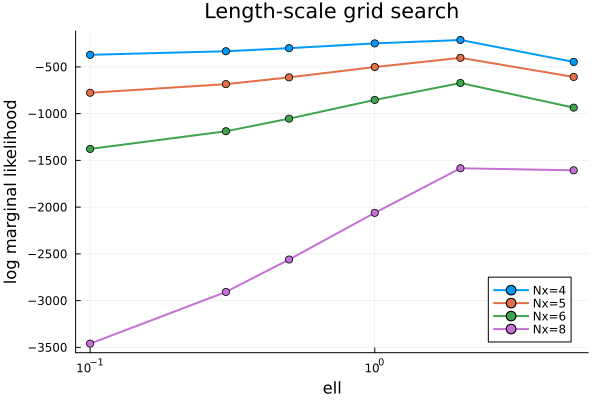

In [7]:
# ============================================================
# Visualization 1: LML versus ell
# ============================================================

p_lml = plot(
    xlabel="ell",
    ylabel="log marginal likelihood",
    xscale=:log10,
    marker=:circle,
    lw=2,
    legend=:best,
    title="Length-scale grid search"
)

for r in results
    plot!(
        p_lml,
        ell_grid,
        r.lml;
        marker=:circle,
        lw=2,
        label="Nx=$(r.Nx)"
    )
end

display(p_lml)


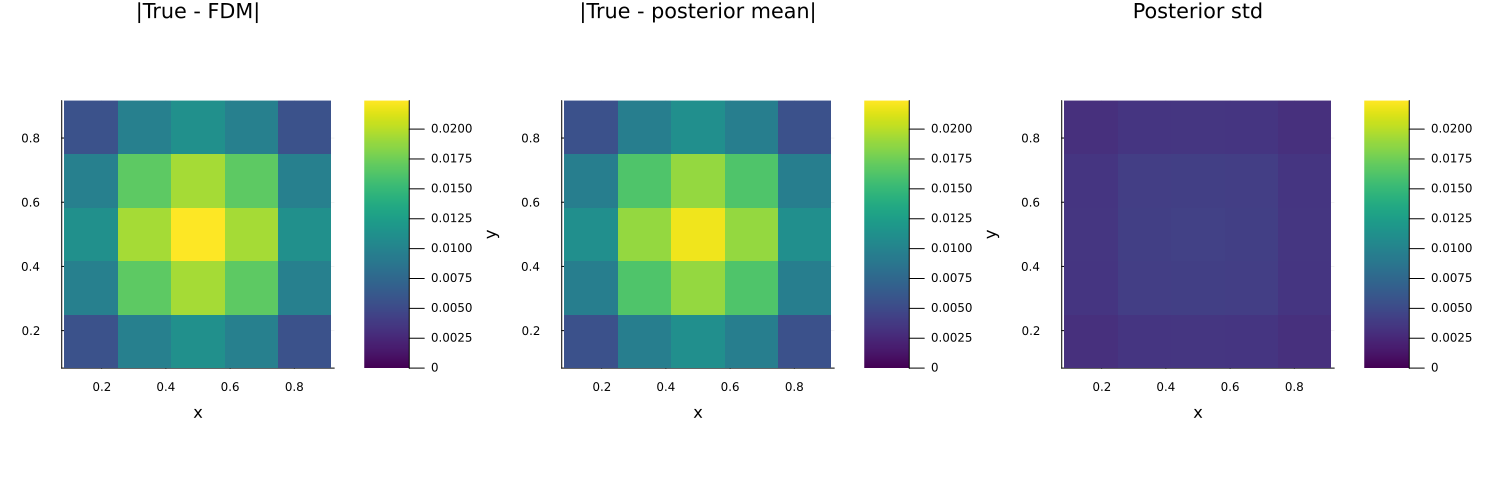


Nx=5, h=0.16667, z=0.500
selected ell = 2.0000
sigma_f      = 1.02239
C_hat        = 327.332
max FDM error  = 0.0223892
max post error = 0.0219143
max post std   = 0.00429268


In [8]:
# ============================================================
# Visualization 2: posterior for one chosen Nx
#
# Change Nx_plot if desired.
# ============================================================

Nx_plot = 5

r = only([rr for rr in results if rr.Nx == Nx_plot])

h, xs, ys, zs, X, Dh, b, u_fdm =
    solve_fdm_helmholtz(Nx_plot)

mu, std_post =
    posterior_helmholtz(
        X, Dh, b, h;
        ell=r.best_ell,
        sigma_f=r.sigma_f,
        C=r.C_hat,
        tau=τ_fixed
    )

u_true_grid = [
    u_exact(x,y,z,k_wave)
    for z in zs, y in ys, x in xs
] |> vec

U_true = reshape(u_true_grid, Nx_plot, Nx_plot, Nx_plot)
U_fdm  = reshape(u_fdm,      Nx_plot, Nx_plot, Nx_plot)
U_post = reshape(mu,         Nx_plot, Nx_plot, Nx_plot)
U_std  = reshape(std_post,   Nx_plot, Nx_plot, Nx_plot)

# middle-z slice
zi = argmin(abs.(zs .- 0.5))
zval = zs[zi]

E_fdm  = abs.(U_true[:,:,zi] .- U_fdm[:,:,zi])
E_post = abs.(U_true[:,:,zi] .- U_post[:,:,zi])
S_std  = U_std[:,:,zi]

# Same color scale so error and std can be compared directly
common_max = maximum(
    vcat(
        vec(E_fdm),
        vec(E_post),
        vec(S_std)
    )
)

cl = (0.0, common_max)

p1 = heatmap(
    xs, ys, E_fdm';
    title="|True - FDM|",
    color=:viridis,
    clim=cl,
    xlabel="x",
    ylabel="y",
    aspect_ratio=:equal
)

p2 = heatmap(
    xs, ys, E_post';
    title="|True - posterior mean|",
    color=:viridis,
    clim=cl,
    xlabel="x",
    ylabel="y",
    aspect_ratio=:equal
)

p3 = heatmap(
    xs, ys, S_std';
    title="Posterior std",
    color=:viridis,
    clim=cl,
    xlabel="x",
    ylabel="y",
    aspect_ratio=:equal
)

fig = plot(
    p1, p2, p3;
    layout=(1,3),
    size=(1500,480),
    margin=2*Plots.mm
)

display(fig)

println()
@printf("Nx=%d, h=%.5f, z=%.3f\n", Nx_plot, h, zval)
@printf("selected ell = %.4f\n", r.best_ell)
@printf("sigma_f      = %.6g\n", r.sigma_f)
@printf("C_hat        = %.6g\n", r.C_hat)
@printf("max FDM error  = %.6g\n", maximum(E_fdm))
@printf("max post error = %.6g\n", maximum(E_post))
@printf("max post std   = %.6g\n", maximum(S_std))


## Full grid-search comparison on a fine test grid

For a fair comparison, fix the training/reference grid at

\[
N_x=5,
\]

and evaluate both methods on the same fine test grid

\[
N_{x,\mathrm{test}}=31.
\]

We compare:

1. **Numerics-informed:** \(C=\widehat C\), \(\sigma_f=\|u_h\|_\infty\), and only \(\ell\) is selected by LML.
2. **Full grid search:** \((\ell,\sigma_f,C)\) are all selected by LML.

The purpose is only to check whether the full grid search can recover a well-calibrated posterior on the fine test grid.


In [9]:
# ============================================================
# Fine test-grid posterior evaluation
# ============================================================

function make_test_grid_3d(Nx_test)
    htest = 1.0 / (Nx_test + 1)
    xs = collect(range(htest, step=htest, length=Nx_test))
    Xtest = [[x,y,z] for z in xs for y in xs for x in xs]
    return htest, xs, Xtest
end

function posterior_on_test_grid(
    Xtrain, Xtest, Dh, b, h;
    ell,
    sigma_f,
    C,
    tau=2
)
    K = kernel_matrix_3d(
        Xtrain, Xtrain;
        ν=ν_fixed,
        ℓ=ell,
        σf=sigma_f
    )

    Kstar = kernel_matrix_3d(
        Xtest, Xtrain;
        ν=ν_fixed,
        ℓ=ell,
        σf=sigma_f
    )

    noise_var = C * h^(2tau)

    A = Hermitian(
        Dh*K*Dh' +
        noise_var*I +
        jitter*I
    )

    L = cholesky(A)
    alpha = L \ b

    # posterior mean on test grid
    Ks = Kstar * Dh'
    mu = Ks * alpha

    # posterior marginal variance on test grid
    # k(x,x) = sigma_f^2 for stationary Matérn kernel
    W = L.L \ Ks'
    var_post = sigma_f^2 .- vec(sum(W.^2, dims=1))
    std_post = sqrt.(max.(var_post, 0.0))

    return mu, std_post
end

function fine_grid_metrics(mu, std, utrue)
    err = abs.(mu .- utrue)

    rmse = sqrt(mean((mu .- utrue).^2))
    linf = maximum(err)
    coverage = mean(err .<= 1.96 .* std)
    mean_halfwidth = mean(1.96 .* std)

    return rmse, linf, coverage, mean_halfwidth
end

println("Fine-grid posterior functions defined.")


Fine-grid posterior functions defined.


In [10]:
# ============================================================
# Nx=5: numerics-informed vs FULL grid search
# ============================================================

Nx_v    = 5
Nx_test = 31

h, xs, ys, zs, X, Dh, b, u_fdm =
    solve_fdm_helmholtz(Nx_v)

_, xtest, Xtest = make_test_grid_3d(Nx_test)

u_true_test = [
    u_exact(x[1], x[2], x[3], k_wave)
    for x in Xtest
]

# ------------------------------------------------------------
# A) Numerics-informed C and sigma; ell only by grid search
# ------------------------------------------------------------

sigma_num = maximum(abs.(u_fdm))

C_num, _, _ =
    estimate_C_coarsening_3d(
        u_fdm, h, Nx_v;
        p=p_order
    )

ell_grid_num = [0.1, 0.3, 0.5, 1.0, 2.0, 5.0]

lml_num = [
    log_marginal_helmholtz(
        X, Dh, b, h;
        ell=ell,
        sigma_f=sigma_num,
        C=C_num,
        tau=τ_fixed
    )
    for ell in ell_grid_num
]

best_num_idx = argmax(lml_num)
best_num_ell = ell_grid_num[best_num_idx]

mu_num, std_num = posterior_on_test_grid(
    X, Xtest, Dh, b, h;
    ell=best_num_ell,
    sigma_f=sigma_num,
    C=C_num,
    tau=τ_fixed
)

rmse_num, linf_num, cov_num, hw_num =
    fine_grid_metrics(
        mu_num,
        std_num,
        u_true_test
    )

# ------------------------------------------------------------
# B) Full grid search over ell, sigma_f, C
# ------------------------------------------------------------

ell_grid_full   = [0.1, 0.3, 0.5, 1.0, 2.0, 5.0]
sigma_grid_full = [0.3, 0.5, 1.0, 2.0, 3.0]
C_grid_full     = [0.01, 0.1, 1.0, 10.0, 100.0, 300.0, 1000.0]

best_lml = -Inf
best_ell = NaN
best_sigma = NaN
best_C = NaN

println("Running full grid search ...")

for ell in ell_grid_full
    for sigma_f in sigma_grid_full
        for C in C_grid_full
            score = try
                log_marginal_helmholtz(
                    X, Dh, b, h;
                    ell=ell,
                    sigma_f=sigma_f,
                    C=C,
                    tau=τ_fixed
                )
            catch
                -Inf
            end

            if score > best_lml
                best_lml = score
                best_ell = ell
                best_sigma = sigma_f
                best_C = C
            end
        end
    end
end

mu_full, std_full = posterior_on_test_grid(
    X, Xtest, Dh, b, h;
    ell=best_ell,
    sigma_f=best_sigma,
    C=best_C,
    tau=τ_fixed
)

rmse_full, linf_full, cov_full, hw_full =
    fine_grid_metrics(
        mu_full,
        std_full,
        u_true_test
    )

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

println("\n==============================================")
println("Nx_train = $(Nx_v), Nx_test = $(Nx_test)")
println("==============================================")

println("\n[A] Numerics-informed + ell grid search")
@printf("ell       = %.4f\n", best_num_ell)
@printf("sigma_f   = %.6g\n", sigma_num)
@printf("C         = %.6g\n", C_num)
@printf("RMSE      = %.6g\n", rmse_num)
@printf("Linf      = %.6g\n", linf_num)
@printf("coverage  = %.3f\n", cov_num)
@printf("mean 95%% half-width = %.6g\n", hw_num)

println("\n[B] Full grid search")
@printf("ell       = %.4f\n", best_ell)
@printf("sigma_f   = %.6g\n", best_sigma)
@printf("C         = %.6g\n", best_C)
@printf("best LML  = %.6g\n", best_lml)
@printf("RMSE      = %.6g\n", rmse_full)
@printf("Linf      = %.6g\n", linf_full)
@printf("coverage  = %.3f\n", cov_full)
@printf("mean 95%% half-width = %.6g\n", hw_full)


Running full grid search ...

Nx_train = 5, Nx_test = 31

[A] Numerics-informed + ell grid search
ell       = 2.0000
sigma_f   = 1.02239
C         = 327.332
RMSE      = 0.0314552
Linf      = 0.13228
coverage  = 0.957
mean 95% half-width = 0.0544539

[B] Full grid search
ell       = 5.0000
sigma_f   = 3
C         = 0.01
best LML  = -390.351
RMSE      = 0.0320823
Linf      = 0.161492
coverage  = 0.827
mean 95% half-width = 0.0411602


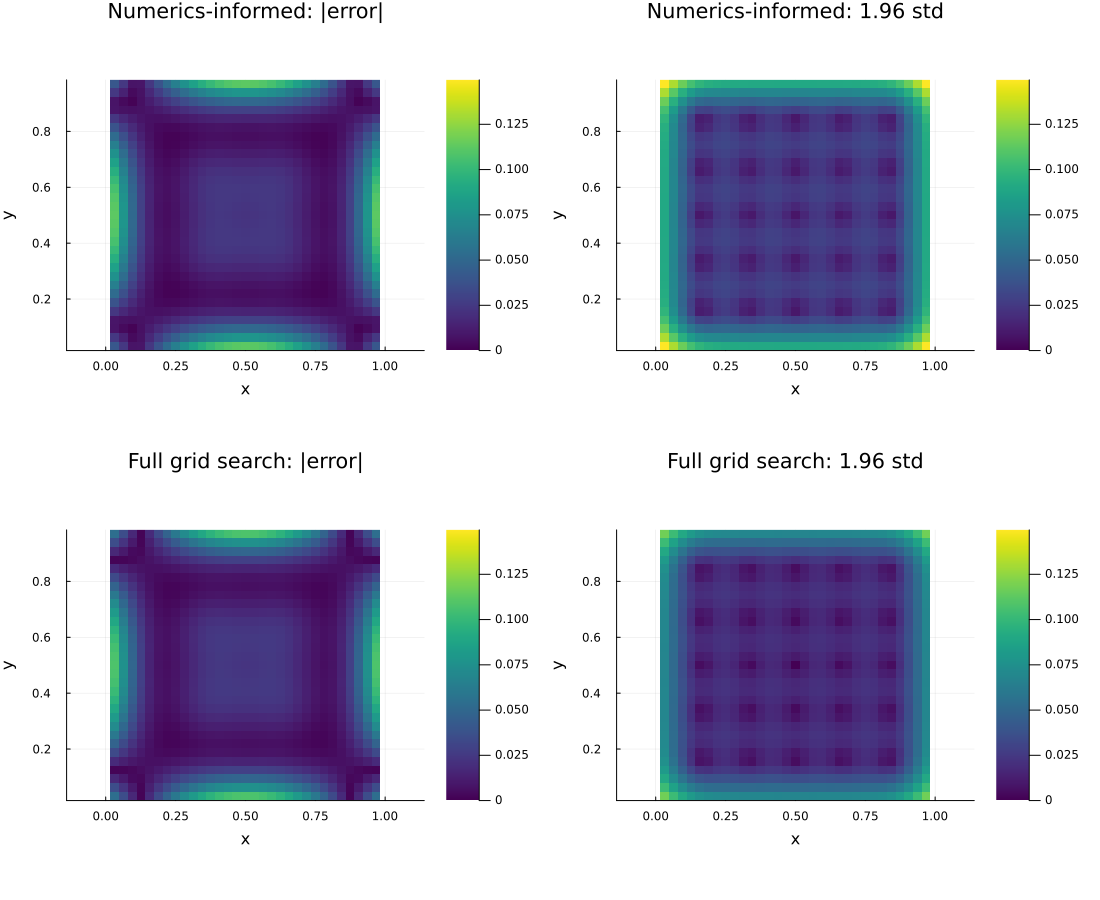

In [11]:
# ============================================================
# Visual comparison on the middle-z test slice
# ============================================================

U_true_test = reshape(u_true_test, Nx_test, Nx_test, Nx_test)
U_num       = reshape(mu_num,      Nx_test, Nx_test, Nx_test)
S_num       = reshape(std_num,     Nx_test, Nx_test, Nx_test)
U_full      = reshape(mu_full,     Nx_test, Nx_test, Nx_test)
S_full      = reshape(std_full,    Nx_test, Nx_test, Nx_test)

zi = argmin(abs.(xtest .- 0.5))

E_num  = abs.(U_true_test[:,:,zi] .- U_num[:,:,zi])
CI_num = 1.96 .* S_num[:,:,zi]

E_full  = abs.(U_true_test[:,:,zi] .- U_full[:,:,zi])
CI_full = 1.96 .* S_full[:,:,zi]

# One common scale across all four panels
common_max = maximum(
    vcat(
        vec(E_num), vec(CI_num),
        vec(E_full), vec(CI_full)
    )
)

cl = (0.0, common_max)

p1 = heatmap(
    xtest, xtest, E_num';
    title="Numerics-informed: |error|",
    color=:viridis,
    clim=cl,
    xlabel="x", ylabel="y",
    aspect_ratio=:equal
)

p2 = heatmap(
    xtest, xtest, CI_num';
    title="Numerics-informed: 1.96 std",
    color=:viridis,
    clim=cl,
    xlabel="x", ylabel="y",
    aspect_ratio=:equal
)

p3 = heatmap(
    xtest, xtest, E_full';
    title="Full grid search: |error|",
    color=:viridis,
    clim=cl,
    xlabel="x", ylabel="y",
    aspect_ratio=:equal
)

p4 = heatmap(
    xtest, xtest, CI_full';
    title="Full grid search: 1.96 std",
    color=:viridis,
    clim=cl,
    xlabel="x", ylabel="y",
    aspect_ratio=:equal
)

fig_compare = plot(
    p1, p2, p3, p4;
    layout=(2,2),
    size=(1100,900),
    margin=2*Plots.mm
)

display(fig_compare)
